# 7-4. Theta -- 정말 튜닝되나, 그리고 이 모델이 뭘 하는 건가

`6-2`에 Theta의 수학적 근거(SES + 드리프트 동치식)는 이미 설명돼 있지만, "튜닝 여부"는 다루지 않았다. 이번엔:

1. Theta 안의 SES 성분이 진짜로 데이터에 맞춰 최적화(튜닝)되는지 확인
2. Theta 모델 자체를 그림으로 설명


## 1. Theta의 SES 성분, 정말 튜닝되나

```python
def fc_theta(values, h=H):
    slope = np.polyfit(np.arange(len(values)), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    return ses_fc + (slope / 2) * np.arange(1, h + 1)
```

**SES의 계산식**: 매 시점마다 `L_t = alpha*y_t + (1-alpha)*L_(t-1)`(직전 평활값과 새 관측치를 alpha 비율로 섞음)로 레벨을 갱신하고, h=1~4 전부 마지막 레벨 `L_n`을 그대로 예측값으로 쓴다(추세가 없으니 h가 커져도 안 바뀜).

**"튜닝"의 실체**: `smoothing_level`(alpha)을 고정하지 않고 `.fit()`하면, statsmodels가 위 식을 alpha별로 다 계산해보고 **학습구간 내 SSE(잔차제곱합)를 최소화하는 alpha를 수치최적화(L-BFGS류)로 찾는다**(`optimized=True`가 기본값). 즉 alpha 하나짜리 값이지만 그리드서치가 아니라 진짜 최적화 문제를 푼다. origin마다 alpha가 뭐가 나오는지, 임의 고정값(0.3)보다 SSE가 낮은지 확인한다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing

H = 4
MIN_TRAIN = 20
TARGET_VAR = "X3_l1"

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
origins = list(range(MIN_TRAIN, n - H + 1))

sample_origins = [origins[0], origins[len(origins) // 3], origins[2 * len(origins) // 3], origins[-1]]
rows = []
for o in sample_origins:
    train = vals[:o]
    fit_opt = ExponentialSmoothing(train, trend=None, initialization_method="estimated").fit()
    fit_fixed = ExponentialSmoothing(train, trend=None, initialization_method="estimated").fit(smoothing_level=0.3, optimized=False)
    rows.append({
        "origin": o, "튜닝된 알파": round(fit_opt.params["smoothing_level"], 4),
        "SSE(튜닝)": round(fit_opt.sse, 1), "SSE(알파=0.3 고정)": round(fit_fixed.sse, 1),
        "튜닝이 더 나음": fit_opt.sse < fit_fixed.sse,
    })
display(pd.DataFrame(rows))


,origin,튜닝된 알파,SSE(튜닝),SSE(알파=0.3 고정),튜닝이 더 나음
0,20,1.0,67010.0,303620.1,True
1,32,1.0,105459.9,388024.9,True
2,44,1.0,219503.6,724805.4,True
3,56,1.0,587437.9,1823485.1,True


**확인됨**: 임의 고정값보다 튜닝된 알파의 SSE가 모든 origin에서 훨씬 낮다 -- 하드코딩이 아니라 실제 최적화다.

### 흥미로운 부작용

`X3_l1`은 4개 origin 전부 **알파가 정확히 1.0**이다. 우연인지 전체 origin과 다른 변수로 확인한다.


In [2]:
def alpha_profile(var):
    v = raw[["quarter", var]].dropna()[var].values.astype(float)
    nn = len(v)
    origs = list(range(MIN_TRAIN, nn - H + 1))
    alphas = []
    for o in origs:
        fit = ExponentialSmoothing(v[:o], trend=None, initialization_method="estimated").fit()
        alphas.append(fit.params["smoothing_level"])
    return np.array(alphas)

check_vars = ["X3_l1", "X6_l1", "X2"]
profile_rows = []
for v in check_vars:
    a = alpha_profile(v)
    profile_rows.append({
        "변수": v, "origin 수": len(a), "알파 최소": round(a.min(), 4), "알파 최대": round(a.max(), 4),
        "알파 평균": round(a.mean(), 4), "알파=1.0인 비율(%)": round(100 * np.mean(a > 0.999), 1),
    })
display(pd.DataFrame(profile_rows))


,변수,origin 수,알파 최소,알파 최대,알파 평균,알파=1.0인 비율(%)
0,X3_l1,37,1.0,1.0000,1.000,100.0
1,X6_l1,40,0.0,0.9468,0.847,0.0
2,X2,37,1.0,1.0000,1.000,100.0


**해석**: `X3_l1`, `X2`는 모든 origin에서 알파=1.0으로 수렴하지만 `X6_l1`은 0~0.95로 다양하다. 알파=1.0은 "최근값 가중치 100%" -- **SES가 사실상 naive와 같아진다는 뜻**이다. 튜닝은 정상 작동하지만 결과가 경계값에 도달할 뿐이라, `X3_l1`에서 Theta가 naive와 다른 부분은 전적으로 드리프트항(`slope/2*h`)에서만 나온다.


### 왜 하필 alpha=1로 수렴하나

"변동이 커서"라는 말만으로는 근거가 약하다 -- alpha를 직접 훑어서 SSE가 정말 1.0에서 최소인지, 그리고 `X3_l1`이 왜 그런 성질을 갖는지 확인한다.


In [3]:
for alpha_try in [0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 1.0]:
    fit = ExponentialSmoothing(vals[:56], trend=None, initialization_method="estimated").fit(smoothing_level=alpha_try, optimized=False)
    print(f"alpha={alpha_try}: SSE={fit.sse:,.0f}")

print()
raw_acf1 = pd.Series(vals).autocorr(lag=1)
diff_acf1 = pd.Series(np.diff(vals)).autocorr(lag=1)
print(f"X3_l1 원계열 lag-1 자기상관: {raw_acf1:.3f} (1에 가까울수록 랜덤워크에 가까움)")
print(f"1차차분한 계열의 lag-1 자기상관: {diff_acf1:.3f}")


alpha=0.1: SSE=3,739,490
alpha=0.3: SSE=1,823,485
alpha=0.5: SSE=1,169,565
alpha=0.7: SSE=842,530
alpha=0.9: SSE=653,024
alpha=0.99: SSE=593,371
alpha=1.0: SSE=587,489

X3_l1 원계열 lag-1 자기상관: 0.934 (1에 가까울수록 랜덤워크에 가까움)
1차차분한 계열의 lag-1 자기상관: 0.403


**확인됨**: alpha를 0.1→1.0으로 올릴수록 SSE가 **단조감소**한다 -- 1.0이 우연한 경계값이 아니라 진짜 전역최소다.

**근본 원인**: `X3_l1` 원계열의 lag-1 자기상관이 **0.93**으로 1에 매우 가깝다 -- 이건 "다음 분기 값이 지난 분기 값과 거의 같은 수준에서 조금씩만 바뀐다"는, **랜덤워크에 가까운 성질**이다. 랜덤워크에서는 이론적으로도 과거를 평활(smoothing)하는 것보다 **가장 최근 값을 그대로 쓰는 게 SSE를 최소화**한다 -- alpha=1이 최적인 이유가 우연이 아니라 이 변수의 통계적 성질에서 나온다. 실제로 `6-4`/`6-5`의 auto-ARIMA도 이 변수에 `d=1`(1차차분 필요)을 선택해왔는데, 이것도 같은 성질(비정상성)을 다른 각도에서 확인해준 것이다.


## 2. Theta 모델 자체 설명

정식 Theta(Assimakopoulos & Nikolopoulos, 2000)는 원계열에 두 개의 "theta 선"을 만든다:
- **theta=0 선**: 원계열의 장기 선형추세만 남긴 직선
- **theta=2 선**: 원계열의 국소적 굴곡을 2배로 증폭한 선(SES로 이 선을 예측)

이 둘을 50:50 평균한 게 최종 예측이며, Hyndman & Billah(2003)이 이게 **"SES 예측 + 기울기 절반 x h"**와 수학적으로 동치임을 증명했다. `fc_theta`는 이 동치식을 바로 쓴다 -- 축약이 아니라 증명된 등가 계산이다.


## 3. 이미지화 -- theta=0 선 / theta=2 선 / 최종 Theta 비교

theta=0 선과 theta=2 선을 실제로 만들어 평균 낸 값이 `fc_theta` 동치식과 일치하는지 확인하고, 세 선을 겹쳐서 본다. 예측구간이 과거구간(56분기)에 묻히지 않도록 **최근 16분기+예측 4분기만 확대**한다.


두 theta선 평균  : [946.992 951.409 955.826 960.242]
동치식(SES+drift): [946.992 951.409 955.826 960.242]
완전히 일치: True


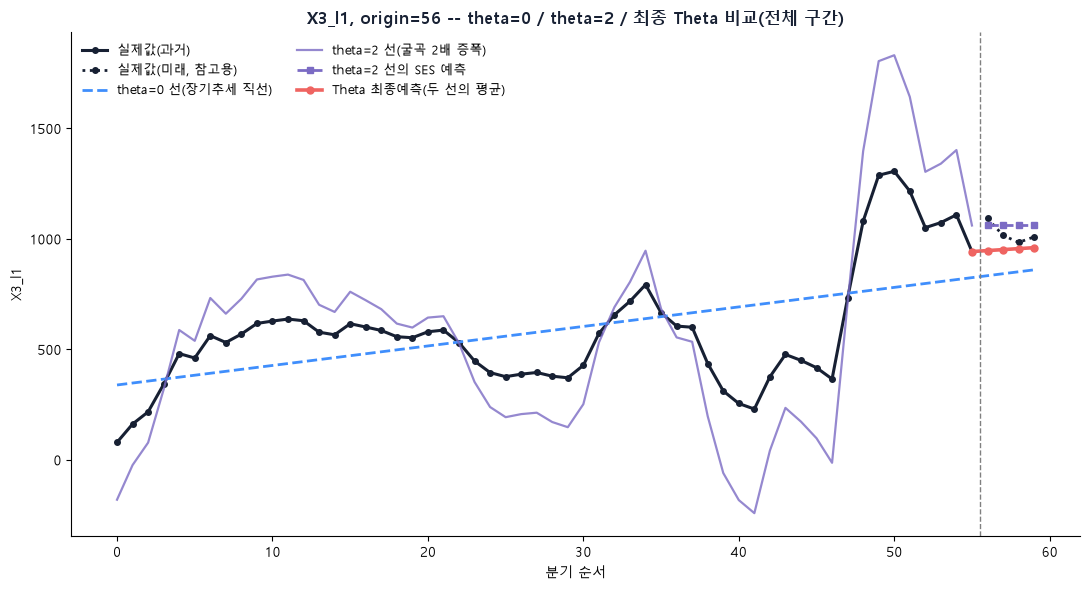

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

demo_origin = origins[-1]
train = vals[:demo_origin]
actual_future = vals[demo_origin:demo_origin + H]
n = len(train)
t = np.arange(n)

# theta=0 선: 선형추세 직선
b, a = np.polyfit(t, train, 1)
theta0_hist = a + b * t
theta0_fc = a + b * np.arange(n, n + H)

# theta=2 선: 2*Y - 추세선(국소굴곡 2배 증폭), 미래는 이 계열에 SES
theta2_hist = 2 * train - theta0_hist
ses_on_theta2 = ExponentialSmoothing(theta2_hist, trend=None, initialization_method="estimated").fit()
theta2_fc = np.asarray(ses_on_theta2.forecast(H))

# 최종 Theta 예측 = 두 선의 평균
theta_final_fc = 0.5 * theta0_fc + 0.5 * theta2_fc

# 기존 동치식(코드에서 실제 쓰는 방식)과 비교
ses_fit = ExponentialSmoothing(train, trend=None, initialization_method="estimated").fit()
ses_fc = np.asarray(ses_fit.forecast(H))
shortcut_theta_fc = ses_fc + (b / 2) * np.arange(1, H + 1)

print("두 theta선 평균  :", np.round(theta_final_fc, 3))
print("동치식(SES+drift):", np.round(shortcut_theta_fc, 3))
print("완전히 일치:", np.allclose(theta_final_fc, shortcut_theta_fc))


def plot_theta_lines(zoom, title_suffix):
    zoom_start = n - zoom if zoom is not None else 0
    hist_x = np.arange(zoom_start, n)
    fc_x = np.arange(n, n + H)

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.plot(hist_x, train[zoom_start:], color="#172033", linewidth=2.2, marker="o", markersize=4, label="실제값(과거)")
    ax.plot(fc_x, actual_future, color="#172033", linewidth=2, linestyle=":", marker="o", markersize=4, label="실제값(미래, 참고용)")

    theta0_zoom = np.concatenate([theta0_hist[zoom_start:], theta0_fc])
    ax.plot(np.concatenate([hist_x, fc_x]), theta0_zoom, color="#3F8EFC", linewidth=2, linestyle="--", label="theta=0 선(장기추세 직선)")

    ax.plot(hist_x, theta2_hist[zoom_start:], color="#7B6BC4", linewidth=1.6, alpha=0.8, label="theta=2 선(굴곡 2배 증폭)")
    ax.plot(fc_x, theta2_fc, color="#7B6BC4", linewidth=2, linestyle="--", marker="s", markersize=4, label="theta=2 선의 SES 예측")

    ax.plot([hist_x[-1], *fc_x], [train[-1], *theta_final_fc], color="#EF6461", linewidth=2.6, marker="o", markersize=5, label="Theta 최종예측(두 선의 평균)")

    ax.axvline(n - 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("분기 순서")
    ax.set_ylabel(TARGET_VAR)
    ax.set_title(f"{TARGET_VAR}, origin={demo_origin} -- theta=0 / theta=2 / 최종 Theta 비교({title_suffix})", fontsize=12.5, fontweight="bold", color="#172033")
    ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()


plot_theta_lines(zoom=None, title_suffix="전체 구간")


**보이는 것**: 파란 점선(theta=0)은 완만한 직선, 보라선(theta=2)은 굴곡을 2배 증폭해 원계열보다 훨씬 크게 출렁인다. 빨강(최종 Theta)은 이 둘의 평균으로 중간 성격을 띤다. 직접 계산한 값과 `fc_theta` 동치식 결과가 소수점까지 완전히 일치함도 확인했다.

아래는 같은 걸 **최근 16분기+예측 4분기만 확대**해서 본 것 -- 예측구간이 과거 56분기에 묻히지 않아 세 선의 관계가 더 잘 보인다.


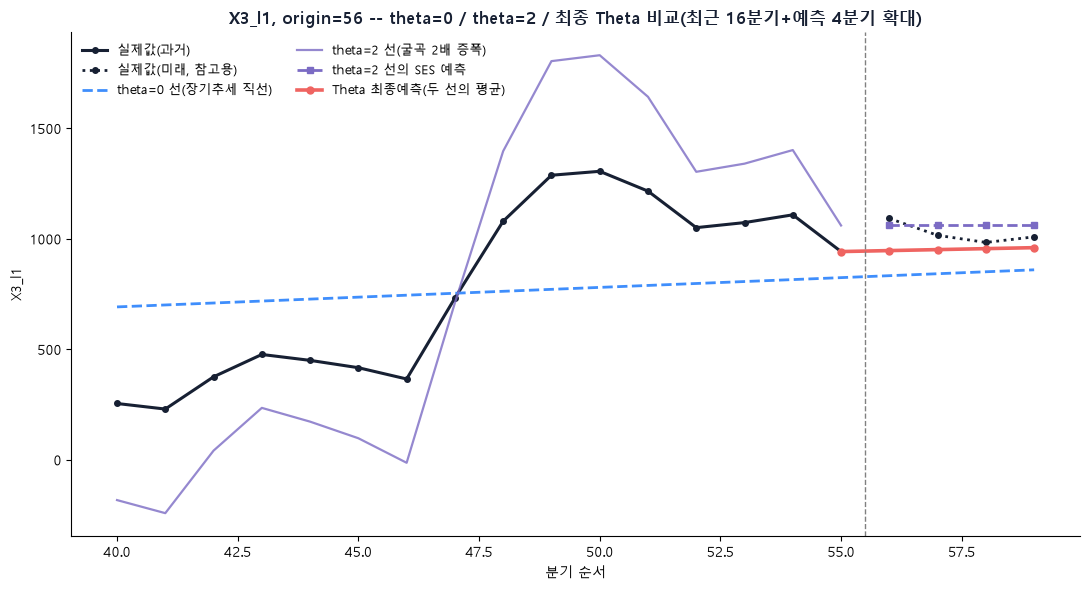

In [5]:
plot_theta_lines(zoom=16, title_suffix="최근 16분기+예측 4분기 확대")


## 4. 결론

- **Theta의 SES 성분은 진짜로 튜닝된다** -- 매 origin마다 SSE 최소화로 알파를 다시 찾고, 임의 고정값보다 확실히 낫다. 하드코딩이 아니다.
- **다만 `X3_l1`에서는 튜닝 결과가 항상 알파=1.0(naive와 동일)으로 수렴한다** -- `X6_l1`은 알파가 다양하게 나오므로 statsmodels 문제가 아니다. alpha를 직접 훑어보면 SSE가 1.0까지 단조감소해 진짜 전역최소이고, 원인은 `X3_l1`의 lag-1 자기상관이 0.93으로 **랜덤워크에 가까운 성질** -- 이런 데이터는 이론적으로도 평활보다 마지막값 그대로가 SSE를 최소화한다(auto-ARIMA가 이 변수에 `d=1`을 선택해온 것과 같은 맥락).
- **모델 설명**: Theta = "장기추세 직선"과 "국소굴곡 증폭선(SES)"의 50:50 평균이며, Hyndman & Billah(2003) 동치식(SES + 기울기/2 x h)으로 정확히 계산된다.
- **이미지로 확인**: theta=0/theta=2를 각각 그려 평균 낸 값이 `fc_theta` 동치식과 소수점까지 일치 -- `X3_l1`에서는 theta=2쪽(SES)이 사실상 마지막 값 고정이라 최종 예측이 추세 직선 쪽으로 크게 좌우된다.
